# Week 4 Take-Home
**Name:** Steven Li  
**NetID:** sl10429  
**Section:** 2 (Thursday)

## SQL Basics for Data Science
### Exploring the LEGO Database

Attribution: Data from the LEGO Database, originally collected by [Rebrickable](https://rebrickable.com/downloads/), a community website that tracks every official LEGO set, part and color. We use a snapshot of the data compiled by Rachael Tatman, which covers LEGO sets released up to 2017. The notebook reads a public copy of the CSV files from GitHub, so it runs in Google Colab with nothing to download.

### In this notebook

LEGO has released thousands of sets since 1950. Information about sets, themes, parts and colors is spread over eight connected tables, which makes it a good place to practice **SQL**, the language data scientists use to ask questions of databases. The slides introduce each idea; this notebook is where **you** write the queries. Everything here is also what data science interviews test, from the basics to window functions.

1. Relational databases and the LEGO tables
2. Selecting and filtering: `SELECT`, `WHERE`, `ORDER BY`
3. Summarizing: aggregates, `GROUP BY`, `HAVING`, `CASE WHEN`
4. Combining tables: `JOIN`, `LEFT JOIN`, self joins
5. CTEs and window functions: `WITH`, ranking, `LAG`, running totals
6. Putting it together: building a complex query step by step

**Data Stories:** 1 The Largest LEGO Sets Ever Made, 2 Are LEGO Sets Getting Bigger?, 3 Which Themes Has LEGO Built the Most Sets For?, 4 The Colors of LEGO.

**How to use this notebook**

- **Predict:** post your guess in the Zoom chat before running the next cell.
- **Your turn:** write the query in the empty cell below it. Many ask you to write a question in two different ways: run both and compare. Open **Hint** if you are stuck, and **Answer** only to check.
- **Insight:** hidden until you have answered. Write your own one-sentence insight first.
- **Exercise:** homework, to finish after class. Exercise 5 is a set of classic interview questions.

### Running this notebook in Google Colab

- **Open it:** go to [colab.research.google.com](https://colab.research.google.com), choose **File > Upload notebook** (or **Open notebook > GitHub**) and select this notebook.
- **Nothing to install or download:** `sqlite3`, `pandas` and `matplotlib` come with Colab, and the LEGO data is read straight from the web.
- **Run the cells in order** with **Shift + Enter**, starting from the top.
- **The database lives in memory.** If Colab disconnects or you restart the runtime, click on the cell you were working on and choose **Runtime > Run before** to rebuild it.
- **Save your work:** choose **File > Save a copy in Drive** before you start, so your answers are kept.

## 1. Relational Databases

A **relational database** stores data in several connected **tables**. Each table has a **primary key** (one unique value per row, such as `sets.set_num`) and can have **foreign keys** that point to another table (such as `sets.theme_id`, which points to `themes.id`). We use **SQLite**, which comes built into Python.

How the LEGO tables connect (each arrow is a foreign key pointing to a primary key):

```
themes.id              <--  sets.theme_id
themes.id              <--  themes.parent_id     (a theme can belong to a bigger theme)
sets.set_num           <--  inventories.set_num
inventories.id         <--  inventory_parts.inventory_id
parts.part_num         <--  inventory_parts.part_num
colors.id              <--  inventory_parts.color_id
part_categories.id     <--  parts.part_cat_id
```

Keep this map in mind. In Section 4 we follow these arrows to combine tables.

### Loading the LEGO tables

First, import the libraries. `sqlite3` lets Python talk to a SQLite database, `pandas` displays our results as tables, and `matplotlib` draws charts. The three color names are the colors used on the slides.

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)

# Chart colors used in the slides
PURPLE = "#5A2D8C"   # the main bars
GRAY   = "#C9C4D1"   # bars we want to set apart
ORANGE = "#E8A93A"   # one bar to highlight

The LEGO data is eight CSV files stored in a public GitHub folder. The code below reads each file straight from that link with `pd.read_csv()`, creates an empty database in memory, and copies each file into it as a table. The first run takes about 10 to 20 seconds, because `inventory_parts` has more than half a million rows.

**Predict:** LEGO has been making sets since the 1950s. How many different sets do you think are in this database? Write down a number, then run the next cell and look at the `sets` row.

In [2]:
# Public copy of the LEGO CSV files (2017 snapshot) on GitHub
DATA_URL = ("https://raw.githubusercontent.com/shalakasaraogi/"
            "lego-database-inventory-management/master/csv%20files/")

tables = ["sets", "themes", "inventories", "inventory_parts",
          "parts", "part_categories", "colors", "inventory_sets"]

conn = sqlite3.connect(":memory:")   # a database that lives in memory while the notebook runs

for table in tables:
    df = pd.read_csv(DATA_URL + f"{table}.csv")
    df.to_sql(table, conn, index=False)
    print(f"{table:<16} {len(df):>8,} rows")

sets               11,673 rows
themes                614 rows


inventories        11,681 rows


inventory_parts   580,251 rows
parts              25,993 rows
part_categories        57 rows


colors                135 rows


inventory_sets      2,846 rows


Next, a small helper function. `run()` sends a SQL query to the database and returns the answer as a pandas DataFrame, which displays nicely in the notebook. From now on, every query in this notebook is written inside `run(""" ... """)`.

The triple quotes let us write a query over several lines, which makes it much easier to read.

In [3]:
def run(query):
    """Run a SQL query on the LEGO database and return the result as a DataFrame."""
    sql_lines = [line for line in query.splitlines()
                 if line.strip() and not line.strip().startswith("--")]
    if not sql_lines:                       # the cell only has comments so far
        print("This cell has no SQL yet. Write your query and run it again.")
        return None
    return pd.read_sql_query(query, conn)

## 2. Selecting and Filtering: SELECT, WHERE, ORDER BY

`SELECT` says **which columns**, `FROM` says **which table**. `*` means all columns, and `LIMIT 5` shows only the first 5 rows, which is good practice on a new table. Keywords in capitals are a convention, not a rule.

In [4]:
run("""
SELECT *
FROM sets
LIMIT 5
""")

,set_num,name,year,theme_id,num_parts
0,00-1,Weetabix Castle,1970,414,471
1,0011-2,Town Mini-Figures,1978,84,12
2,0011-3,Castle 2 for 1 Bonus Offer,1987,199,2
3,0012-1,Space Mini-Figures,1979,143,12
4,0013-1,Space Mini-Figures,1979,143,12


List only the columns you need. You can also calculate a new column and name it with `AS` (an **alias**). Here: how old is each set in 2026?

In [5]:
run("""
SELECT name,
       year,
       2026 - year AS age_in_years
FROM sets
LIMIT 5
""")

,name,year,age_in_years
0,Weetabix Castle,1970,56
1,Town Mini-Figures,1978,48
2,Castle 2 for 1 Bonus Offer,1987,39
3,Space Mini-Figures,1979,47
4,Space Mini-Figures,1979,47


`DISTINCT` removes duplicate rows, which answers "which values appear in this column?"

**Your turn 1: Meet the colors.** Show the `name` and `rgb` columns of the first 10 rows of `colors`, and rename `rgb` to `hex_code`. Then write a second query with `SELECT DISTINCT is_trans`. What do its values mean, and what is odd about the very first color in the table?

<details>
  <summary>Hint</summary>

`SELECT name, rgb AS hex_code FROM colors LIMIT 10`. For the second query, replace the column list with `DISTINCT is_trans`.

</details>

<details>
  <summary>Answer</summary>

```sql
SELECT name, rgb AS hex_code
FROM colors
LIMIT 10
```

```sql
SELECT DISTINCT is_trans
FROM colors
```

`is_trans` has only two values: `'f'` (a solid color) and `'t'` (a transparent color). The first color is called **Unknown**, with hex code `0033B2`: real data often has a placeholder row for values nobody recorded.

</details>

In [6]:
display(run("""
SELECT name, rgb AS hex_code
FROM colors
LIMIT 10
"""))

display(run("""
SELECT DISTINCT is_trans
FROM colors
"""))

,name,hex_code
0,Unknown,0033B2
1,Black,05131D
2,Blue,0055BF
3,Green,237841
4,Dark Turquoise,008F9B
5,Red,C91A09
6,Dark Pink,C870A0
7,Brown,583927
8,Light Gray,9BA19D
9,Dark Gray,6D6E5C


,is_trans
0,f
1,t


**My answer:** `is_trans` has two values: `'f'` for a solid color and `'t'` for a transparent one. The first color, **Unknown** (`0033B2`), is a placeholder row for a color that nobody recorded.

### Filtering rows with WHERE

`WHERE` keeps only the rows that pass a condition (the operators are on the slide). Text values go inside **single quotes**, numbers do not.

**Predict:** how many LEGO sets have more than 5,000 parts? Write down a number, then run the next cell.

In [7]:
run("""
SELECT name, year, num_parts
FROM sets
WHERE num_parts > 5000
""")

,name,year,num_parts
0,Millennium Falcon - UCS,2007,5195
1,Taj Mahal,2008,5922
2,Window Exploration Bag,2010,5200
3,Star Wars / M&M Mosaic - Promo Set,2005,5461


**Your turn 2: Does the boundary matter?** Find the sets released from 2010 to 2016 with at least 4,000 parts. Write it three ways and compare how many rows each returns:

1. with `BETWEEN 2010 AND 2016`
2. with `year >= 2010 AND year <= 2016`
3. with `year > 2010 AND year < 2016`

<details>
  <summary>Hint</summary>

Keep `AND num_parts >= 4000` in all three versions and only change the condition on `year`. Look at the `year` column of the first result.

</details>

<details>
  <summary>Answer</summary>

```sql
SELECT name, year, num_parts
FROM sets
WHERE year BETWEEN 2010 AND 2016
  AND num_parts >= 4000
ORDER BY num_parts DESC
```

Versions 1 and 2 return the same 7 sets, because `BETWEEN` **includes** both ends. Version 3 returns **0 rows**: every one of the 7 sets is from 2010 or 2016, exactly the two years that `>` and `<` leave out. One character can change your answer completely.

</details>

In [8]:
display(run("""
SELECT name, year, num_parts
FROM sets
WHERE year BETWEEN 2010 AND 2016
  AND num_parts >= 4000
ORDER BY num_parts DESC
"""))

display(run("""
SELECT name, year, num_parts
FROM sets
WHERE year >= 2010 AND year <= 2016
  AND num_parts >= 4000
ORDER BY num_parts DESC
"""))

display(run("""
SELECT name, year, num_parts
FROM sets
WHERE year > 2010 AND year < 2016
  AND num_parts >= 4000
ORDER BY num_parts DESC
"""))

,name,year,num_parts
0,Window Exploration Bag,2010,5200
1,Firehouse Headquarters,2016,4640
2,Personalised Mosaic Portrait,2016,4501
3,Tower Bridge,2010,4295
4,Big Ben,2016,4166
5,The Disney Castle,2016,4060
6,Death Star,2016,4023


,name,year,num_parts
0,Window Exploration Bag,2010,5200
1,Firehouse Headquarters,2016,4640
2,Personalised Mosaic Portrait,2016,4501
3,Tower Bridge,2010,4295
4,Big Ben,2016,4166
5,The Disney Castle,2016,4060
6,Death Star,2016,4023


,name,year,num_parts


**My answer:** Versions 1 and 2 return the same 7 sets, because `BETWEEN` includes both ends. Version 3 returns 0 rows: all 7 sets were released in 2010 or 2016, the two years that `>` and `<` leave out.

In a `LIKE` pattern, `%` matches any number of characters and `_` matches exactly one, so `'%Falcon%'` finds names that contain "Falcon" anywhere.

**Your turn 3: Pattern hunt.** Predict which pattern finds more sets, then check. Wrap each query as `SELECT COUNT(*) FROM sets WHERE ...` to count the rows (we meet `COUNT` properly in Section 3).

1. `name LIKE '%Train'` or `name LIKE '%Train%'`?
2. `name LIKE 'Star Wars%'` or `name LIKE '%Star Wars%'`?

Then look at a few rows that the bigger pattern finds but the smaller one does not.

<details>
  <summary>Hint</summary>

`%` at the start means "anything before", `%` at the end means "anything after". To see the extra rows, combine both: `WHERE name LIKE '%Train%' AND name NOT LIKE '%Train'`.

</details>

<details>
  <summary>Answer</summary>

```sql
SELECT COUNT(*)
FROM sets
WHERE name LIKE '%Train%'
```

`'%Train'` finds 43 sets but `'%Train%'` finds 187, because it also matches "Train Engine Shed", "My First Train Set" and so on. `'Star Wars%'` finds 57 sets; `'%Star Wars%'` finds 199, including books, watches and clocks such as "LEGO Star Wars: The Visual Dictionary". Where you put `%` decides what you are really asking.

</details>

In [9]:
display(run("""
SELECT (SELECT COUNT(*) FROM sets WHERE name LIKE '%Train')      AS ends_with_train,
       (SELECT COUNT(*) FROM sets WHERE name LIKE '%Train%')     AS contains_train,
       (SELECT COUNT(*) FROM sets WHERE name LIKE 'Star Wars%')  AS starts_with_star_wars,
       (SELECT COUNT(*) FROM sets WHERE name LIKE '%Star Wars%') AS contains_star_wars
"""))

run("""
SELECT name, year
FROM sets
WHERE name LIKE '%Train%'
  AND name NOT LIKE '%Train'
LIMIT 10
""")

,ends_with_train,contains_train,starts_with_star_wars,contains_star_wars
0,43,187,57,199


,name,year
0,Train Engine Shed,2003
1,Train Connection Wire,2003
2,Train Level Crossing,2003
3,Electric Train Motor 9V (My Own Train),2002
4,High Speed Train Locomotive,2004
5,High Speed Train Car,2004
6,Train Accessory Set,2013
7,My First Train Set,2013
8,Deluxe Train Set,2013
9,Train Wheels,1977


**My answer:** `'%Train'` finds 43 sets and `'%Train%'` finds 187. The bigger pattern also catches names such as "Train Engine Shed" and "Electric Train Motor 9V (My Own Train)". `'Star Wars%'` finds 57 sets and `'%Star Wars%'` finds 199. The position of `%` decides what you are really asking.

**Your turn 4: Nothing equals NULL.** A missing value is called `NULL`. In `themes`, a theme with no `parent_id` is a top level theme, such as "Technic". Count the top level themes in two ways and compare:

1. `WHERE parent_id IS NULL`
2. `WHERE parent_id = NULL`

Then count the themes that **do** have a parent.

<details>
  <summary>Hint</summary>

Use `SELECT COUNT(*) FROM themes WHERE ...` for each version. The opposite of `IS NULL` is `IS NOT NULL`.

</details>

<details>
  <summary>Answer</summary>

```sql
SELECT COUNT(*)
FROM themes
WHERE parent_id IS NULL
```

`IS NULL` finds 111 top level themes. `= NULL` finds **0**, with no error message: `NULL` means "unknown", and nothing is ever equal to an unknown value. `IS NOT NULL` finds the other 503 themes. Always use `IS NULL` and `IS NOT NULL`.

</details>

In [10]:
run("""
SELECT (SELECT COUNT(*) FROM themes WHERE parent_id IS NULL)     AS parent_is_null,
       (SELECT COUNT(*) FROM themes WHERE parent_id = NULL)      AS parent_equals_null,
       (SELECT COUNT(*) FROM themes WHERE parent_id IS NOT NULL) AS has_a_parent
""")

,parent_is_null,parent_equals_null,has_a_parent
0,111,0,503


**My answer:** `IS NULL` finds 111 top level themes. `= NULL` finds 0, with no error, because nothing equals an unknown value. The other 503 themes have a parent. Always use `IS NULL` and `IS NOT NULL`.

### Sorting with ORDER BY

`ORDER BY column DESC` sorts from largest to smallest (`ASC`, the default, does the opposite). Combined with `LIMIT`, it answers every "top N" question. You can sort by several columns: `ORDER BY year DESC, num_parts DESC`.

### Data Story 1: The Largest LEGO Sets Ever Made

Which sets have the most parts? Sorting by `num_parts` in descending order and keeping the top 10 gives the answer in one short query.

**Predict:** which set do you think has the most parts of all time? Post your guess in the Zoom chat before running the next cell.

In [11]:
largest = run("""
SELECT name, year, num_parts
FROM sets
ORDER BY num_parts DESC
LIMIT 10
""")

largest

,name,year,num_parts
0,Taj Mahal,2008,5922
1,Star Wars / M&M Mosaic - Promo Set,2005,5461
2,Window Exploration Bag,2010,5200
3,Millennium Falcon - UCS,2007,5195
4,Firehouse Headquarters,2016,4640
5,Personalised Mosaic Portrait,2016,4501
6,Tower Bridge,2010,4295
7,Big Ben,2016,4166
8,The Disney Castle,2016,4060
9,Death Star,2016,4023


Read the names carefully. Is every one of these a single model that you would build from one set of instructions?

The query result is a normal pandas DataFrame, so everything from Weeks 2 and 3 works on it. Below, `.isin()` gives `True` for the three rows that are not single models, and `np.where()` turns that into a color for each bar.

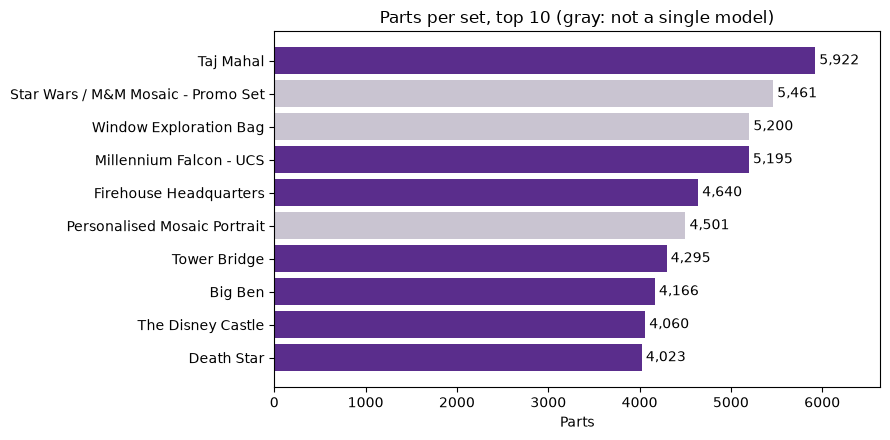

In [12]:
not_models = ["Star Wars / M&M Mosaic - Promo Set", "Window Exploration Bag", "Personalised Mosaic Portrait"]
bar_colors = np.where(largest["name"].isin(not_models), GRAY, PURPLE)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(largest["name"], largest["num_parts"], color=bar_colors)
ax.bar_label(bars, fmt="{:,.0f}", padding=3)
ax.invert_yaxis()                      # largest set at the top
ax.margins(x=0.12)                     # room for the labels
ax.set_title("Parts per set, top 10 (gray: not a single model)")
ax.set_xlabel("Parts")
plt.tight_layout()
plt.show()

#### Insight:

<details>
  <summary>Reveal after you finish the Your turn questions above</summary>

- Only 4 sets have more than 5,000 parts. The largest is the Taj Mahal (2008) with 5,922 parts, followed closely by the Ultimate Collector Series Millennium Falcon (2007).
- Not every row is a single model. "Star Wars / M&M Mosaic - Promo Set" and "Window Exploration Bag" are promotional or bulk collections of bricks. A sorted list is only the start: always read the rows before you report a "largest" or "best".

</details>

### Exercise 1 Sets from your birth year

1. Find all sets released in the year you were born that have more than 500 parts. Show the `name`, `year` and `num_parts` columns.
2. Find all sets whose name contains the word `Castle` and that were released before 1990.

<details>
  <summary>Hints</summary>

1. Combine `year = ...` and `num_parts > 500` with `AND`.
2. Use `name LIKE '%Castle%'` together with `year < 1990`.

</details>

In [13]:
# Change me: the year you were born, for example 1999
BIRTH_YEAR = 2005

if BIRTH_YEAR is None:
    print("Set BIRTH_YEAR to the year you were born, then run this cell again.")
else:
    display(run(f"""
SELECT name, year, num_parts
FROM sets
WHERE year = {int(BIRTH_YEAR)}
  AND num_parts > 500
ORDER BY num_parts DESC
"""))

run("""
SELECT name, year
FROM sets
WHERE name LIKE '%Castle%'
  AND year < 1990
""")

,name,year,num_parts
0,Star Wars / M&M Mosaic - Promo Set,2005,5461
1,Death Star II,2005,3460
2,Skyline,2005,2792
3,XXL 2000 Canister,2005,2000
4,Mobile Crane,2005,1884
5,Sandcrawler,2005,1679
6,Blue Tub,2005,1500
7,FIRST LEGO League Challenge 2005 - Ocean Odyssey,2005,1471
8,Enzo Ferrari 1:10,2005,1357
9,Amusement Park,2005,1339


,name,year
0,Weetabix Castle,1970
1,Castle 2 for 1 Bonus Offer,1987
2,Castle Mini Figures,1978
3,Castle Mini Figures,1984
4,Town Square - Castle Scene,1980
5,Town Square - Castle Scene (Dutch Version),1983
6,Castle,1978
7,Castle Equipment,1989
8,Castle Figures,1983
9,Castle Guard,1987


**My answer:** In 2005 there are 37 sets with more than 500 parts; the largest is the Star Wars / M&M Mosaic - Promo Set (5,461 parts). The second query lists the 16 Castle sets released before 1990.

## 3. Summarizing: Aggregates, GROUP BY, HAVING, CASE WHEN

**Aggregate functions** (`COUNT`, `SUM`, `AVG`, `MIN`, `MAX`) turn many rows into one number. `COUNT(DISTINCT column)` counts different values, and `ROUND(value, 1)` keeps results readable.

**Predict:** what is the average number of parts in a LEGO set? Is it closer to 50, 150 or 500?

In [14]:
run("""
SELECT COUNT(*)                 AS number_of_sets,
       COUNT(DISTINCT theme_id) AS number_of_themes,
       MIN(year)                AS first_year,
       MAX(year)                AS last_year,
       ROUND(AVG(num_parts), 1) AS average_parts
FROM sets
""")

,number_of_sets,number_of_themes,first_year,last_year,average_parts
0,11673,575,1950,2017,162.3


**Your turn 5: Four ways to count.** In **one** query on `sets`, compute `COUNT(*)`, `COUNT(DISTINCT theme_id)`, `COUNT(DISTINCT year)` and `COUNT(DISTINCT name)`, each with a clear alias. Then answer:

1. LEGO's data runs from 1950 to 2017, which is 68 years. Why is the number of distinct years smaller?
2. Why are there fewer distinct names than sets?

Bonus: on `themes`, compare `COUNT(*)` with `COUNT(parent_id)`. What does the difference count?

<details>
  <summary>Hint</summary>

Separate the four aggregates with commas: `SELECT COUNT(*) AS sets, COUNT(DISTINCT year) AS years, ... FROM sets`.

</details>

<details>
  <summary>Answer</summary>

```sql
SELECT COUNT(*)                 AS number_of_sets,
       COUNT(DISTINCT theme_id) AS themes_used,
       COUNT(DISTINCT year)     AS years_with_sets,
       COUNT(DISTINCT name)     AS different_names
FROM sets
```

11,673 sets, 575 themes, 66 years and 10,370 names. Two years (1951 and 1952) have no sets at all, and many names repeat: "Basic Building Set" alone appears 55 times. Bonus: `COUNT(*)` gives 614 themes but `COUNT(parent_id)` gives 503, because `COUNT(column)` skips `NULL`. The difference, 111, is the number of top level themes from Your turn 4.

</details>

In [15]:
display(run("""
SELECT COUNT(*)                 AS number_of_sets,
       COUNT(DISTINCT theme_id) AS number_of_themes,
       COUNT(DISTINCT year)     AS years_with_sets,
       COUNT(DISTINCT name)     AS different_names
FROM sets
"""))

run("""
SELECT COUNT(*)        AS all_themes,
       COUNT(parent_id) AS themes_with_parent
FROM themes
""")

,number_of_sets,number_of_themes,years_with_sets,different_names
0,11673,575,66,10370


,all_themes,themes_with_parent
0,614,503


**My answers:**

1. There are 66 distinct years, not 68. The range 1950 to 2017 covers 68 calendar years, but 1951 and 1952 have no sets at all.
2. Many names repeat. "Basic Building Set" appears 55 times, so the 11,673 sets have only 10,370 different names.

Bonus: `COUNT(*)` counts all 614 themes and `COUNT(parent_id)` counts the 503 that have a parent. The difference, 111, is the number of top level themes, because `COUNT(column)` skips `NULL`.

### GROUP BY: one summary per group

`GROUP BY` splits the rows into groups and calculates the aggregate **separately for each group**, the same idea as `groupby()` in pandas. Rule: every column in `SELECT` must be either inside an aggregate or listed in `GROUP BY`.

### Data Story 2: Are LEGO Sets Getting Bigger?

Many adult fans say that modern sets are much larger than the sets they had as children. Let us check this with data: how many sets were released each year, and how many parts did an average set have?

**Predict:** over the decades, will the number of sets per year go up, go down, or stay about the same? And the average size of a set?

In [16]:
sets_per_year = run("""
SELECT year,
       COUNT(*)                 AS number_of_sets,
       ROUND(AVG(num_parts), 1) AS average_parts
FROM sets
GROUP BY year
ORDER BY number_of_sets DESC
""")

sets_per_year.head()

,year,number_of_sets,average_parts
0,2014,713,169.7
1,2015,665,201.7
2,2012,615,149.8
3,2016,596,253.1
4,2013,593,181.3


A query result is a normal pandas DataFrame, so we can plot it directly: SQL to pull and summarize, Python to visualize. On the left, every year gets a bar and the last year is colored orange. On the right, a second query computes the average set size per decade.

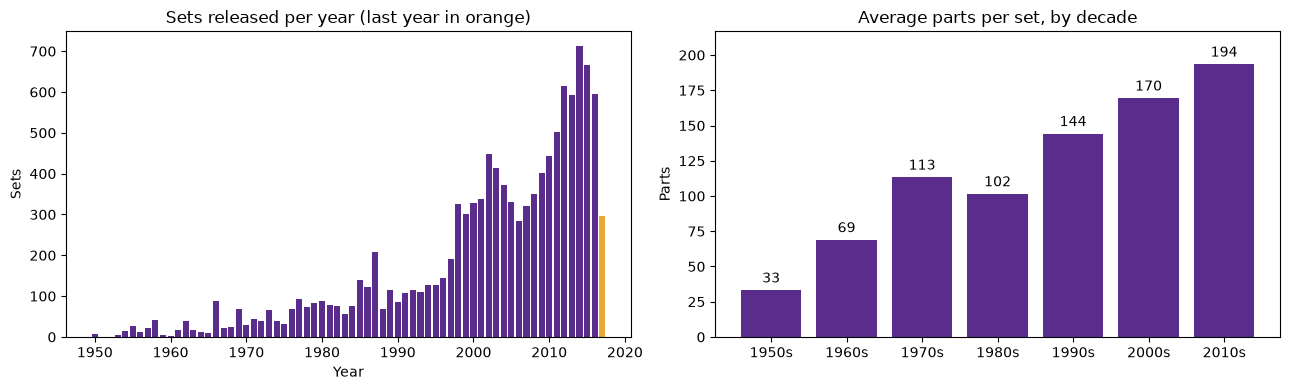

In [17]:
by_decade = run("""
SELECT (year / 10) * 10          AS decade,
       ROUND(AVG(num_parts), 1)  AS average_parts
FROM sets
GROUP BY decade
ORDER BY decade
""")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

year_colors = np.where(sets_per_year["year"] == sets_per_year["year"].max(), ORANGE, PURPLE)
axes[0].bar(sets_per_year["year"], sets_per_year["number_of_sets"], color=year_colors)
axes[0].set_title("Sets released per year (last year in orange)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Sets")

labels = by_decade["decade"].astype(str) + "s"
bars = axes[1].bar(labels, by_decade["average_parts"], color=PURPLE)
axes[1].bar_label(bars, fmt="{:.0f}", padding=3)
axes[1].margins(y=0.12)
axes[1].set_title("Average parts per set, by decade")
axes[1].set_ylabel("Parts")

plt.tight_layout()
plt.show()

Compare the two charts with your prediction. Then look closely at the very last year in the left chart: does anything look strange?

**Your turn 6: Busiest and quietest year.** Which year had the most sets released, and how many? Then change **one word** to find the quietest year.

<details>
  <summary>Hint</summary>

Group by `year`, count the rows, sort by the count, and keep 1 row. For the quietest year, swap `DESC` for `ASC`.

</details>

<details>
  <summary>Answer</summary>

```sql
SELECT year,
       COUNT(*) AS number_of_sets
FROM sets
GROUP BY year
ORDER BY number_of_sets DESC
LIMIT 1
```

The busiest year is 2014, with 713 sets. The quietest is 1960, with only 3. You can sort by an alias you created in `SELECT`, such as `number_of_sets`.

</details>

In [18]:
display(run("""
SELECT year,
       COUNT(*) AS number_of_sets
FROM sets
GROUP BY year
ORDER BY number_of_sets DESC
LIMIT 1
"""))

run("""
SELECT year,
       COUNT(*) AS number_of_sets
FROM sets
GROUP BY year
ORDER BY number_of_sets ASC
LIMIT 1
""")

,year,number_of_sets
0,2014,713


,year,number_of_sets
0,1960,3


**My answer:** 2014 had the most sets, with 713. The quietest year was 1960, with only 3 sets.

#### Insight:

<details>
  <summary>Reveal after you finish the Your turn questions above</summary>

- LEGO never released more than 89 sets in a year during the 1950s and 1960s, but at least 444 sets every year from 2010 to 2016, with a peak of 713 sets in 2014.
- The average set grew from about 160 parts overall to more than 250 parts in 2016 and 2017.
- The drop in 2017 is not real: that year is only partly recorded. Always check where a dataset ends before reading the last point of a trend.
- The average is pulled down by the many small items (polybags, key chains, books) that LEGO also sells, so a typical boxed set is even larger than the line suggests.

</details>

### HAVING: filtering groups

`WHERE` filters **rows before** they are grouped. `HAVING` filters **groups after** they are summarized, so any condition on `COUNT(*)` or `AVG(...)` goes in `HAVING`. The query below finds years in which LEGO released more than 500 sets.

In [19]:
run("""
SELECT year,
       COUNT(*) AS number_of_sets
FROM sets
GROUP BY year
HAVING COUNT(*) > 500
ORDER BY year
""")

,year,number_of_sets
0,2011,503
1,2012,615
2,2013,593
3,2014,713
4,2015,665
5,2016,596


**Your turn 7: WHERE and HAVING in the same query.** Find the years in which the average set had more than 200 parts. Then add `WHERE num_parts > 0` to ignore products with no bricks, and run it again. Which new year appears, and why should we be suspicious of it? Add `COUNT(*)` to your columns to find out.

<details>
  <summary>Hint</summary>

`GROUP BY year HAVING AVG(num_parts) > 200`. The `WHERE` line goes between `FROM` and `GROUP BY`. To keep only years with enough sets, add `AND COUNT(*) >= 50` to the `HAVING` line.

</details>

<details>
  <summary>Answer</summary>

```sql
SELECT year,
       COUNT(*)                 AS number_of_sets,
       ROUND(AVG(num_parts), 1) AS average_parts
FROM sets
WHERE num_parts > 0
GROUP BY year
HAVING AVG(num_parts) > 200
ORDER BY year
```

Without `WHERE` there are 9 years. With `WHERE num_parts > 0` there are 12, and **1960** jumps in with an average of 263 parts, but it has only 2 sets left (one with 476 parts). An average of 2 numbers is not a trend. Adding `AND COUNT(*) >= 50` to `HAVING` removes it. `WHERE` filters rows before grouping, `HAVING` filters groups after.

</details>

In [20]:
display(run("""
SELECT year,
       COUNT(*)                 AS number_of_sets,
       ROUND(AVG(num_parts), 1) AS average_parts
FROM sets
GROUP BY year
HAVING AVG(num_parts) > 200
ORDER BY year
"""))

run("""
SELECT year,
       COUNT(*)                 AS number_of_sets,
       ROUND(AVG(num_parts), 1) AS average_parts
FROM sets
WHERE num_parts > 0
GROUP BY year
HAVING AVG(num_parts) > 200
ORDER BY year
""")

,year,number_of_sets,average_parts
0,1990,85,201.8
1,1996,144,201.6
2,2006,283,246.8
3,2007,321,227.6
4,2008,349,231.6
5,2010,444,210.4
6,2015,665,201.7
7,2016,596,253.1
8,2017,296,260.8


,year,number_of_sets,average_parts
0,1960,2,263.0
1,1990,84,204.2
2,1996,144,201.6
3,2005,323,203.0
4,2006,278,251.3
5,2007,293,249.3
6,2008,329,245.7
7,2009,389,203.9
8,2010,410,227.9
9,2015,603,222.4


**My answer:** 1960 appears only after we drop products with no parts. Its 3 sets include one with 0 parts, so after the `WHERE` only 2 sets are left (50 and 476 parts), which averages 263. An average of 2 numbers is not a trend. Adding `AND COUNT(*) >= 50` to the `HAVING` line removes it.

### CASE WHEN: creating categories

`CASE WHEN` works like `if / elif / else` in Python: SQL checks the conditions from top to bottom and uses the first one that is true. Below, every set gets a size label, then we count each label. The numbers at the start of each label make `ORDER BY` put them in a sensible order.

In [21]:
sizes = run("""
SELECT CASE
           WHEN num_parts = 0     THEN '0. No parts'
           WHEN num_parts < 100   THEN '1. Small (1 to 99)'
           WHEN num_parts < 500   THEN '2. Medium (100 to 499)'
           WHEN num_parts < 1000  THEN '3. Large (500 to 999)'
           ELSE                        '4. Very large (1000+)'
       END AS size_category,
       COUNT(*) AS number_of_sets
FROM sets
GROUP BY size_category
ORDER BY size_category
""")

sizes

,size_category,number_of_sets
0,0. No parts,473
1,1. Small (1 to 99),7241
2,2. Medium (100 to 499),2948
3,3. Large (500 to 999),723
4,4. Very large (1000+),288


The labels we invented with `CASE WHEN` become the bars of a chart. The first bar, products with no parts, is gray.

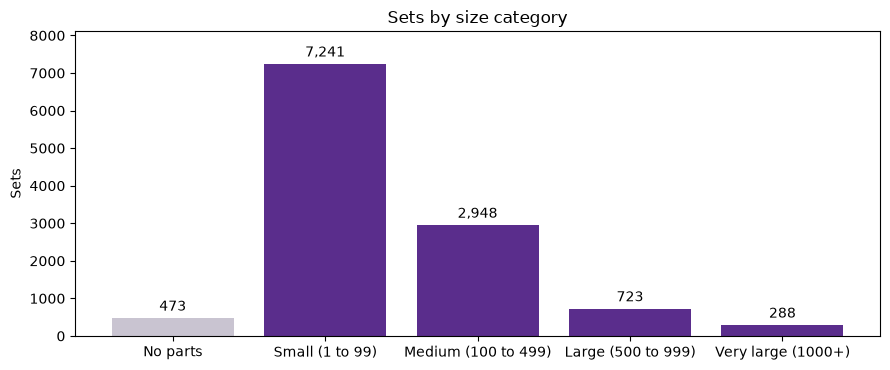

In [22]:
labels = sizes["size_category"].str[3:]           # drop the "0. " sorting prefix
size_colors = [GRAY] + [PURPLE] * (len(sizes) - 1)

fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.bar(labels, sizes["number_of_sets"], color=size_colors)
ax.bar_label(bars, fmt="{:,.0f}", padding=3)
ax.margins(y=0.12)
ax.set_title("Sets by size category")
ax.set_ylabel("Sets")
plt.tight_layout()
plt.show()

**Your turn 8: Count with conditions.** A classic interview pattern: count only some rows inside a `GROUP BY`. For each decade, show the number of sets, the number of **big** sets (1,000 parts or more) and the percentage of sets that are big, rounded to 1 decimal.

Then change `100.0 *` to `100 *` in your percentage. What goes wrong, and why?

<details>
  <summary>Hint</summary>

`SUM(CASE WHEN num_parts >= 1000 THEN 1 ELSE 0 END)` counts the big sets: each big set adds 1, every other set adds 0. The decade is `(year / 10) * 10`. Divide by `COUNT(*)` for the share.

</details>

<details>
  <summary>Answer</summary>

```sql
SELECT (year / 10) * 10 AS decade,
       COUNT(*) AS all_sets,
       SUM(CASE WHEN num_parts >= 1000 THEN 1 ELSE 0 END) AS big_sets,
       ROUND(100.0 * SUM(CASE WHEN num_parts >= 1000 THEN 1 ELSE 0 END) / COUNT(*), 1) AS big_percent
FROM sets
GROUP BY decade
ORDER BY decade
```

There were no sets with 1,000 or more parts before the 1980s, one in the 1980s, and 159 (3.6%) in the 2010s. With `100 *` the percentages become whole numbers (3 instead of 3.6, 0 instead of 0.1): when SQL divides one whole number by another, it throws away the decimals. Writing `100.0` makes the calculation use decimals. This trap appears in many interviews.

</details>

In [23]:
display(run("""
SELECT (year / 10) * 10 AS decade,
       COUNT(*)         AS all_sets,
       SUM(CASE WHEN num_parts >= 1000 THEN 1 ELSE 0 END) AS big_sets,
       ROUND(100.0 * SUM(CASE WHEN num_parts >= 1000 THEN 1 ELSE 0 END) / COUNT(*), 1) AS big_percent
FROM sets
GROUP BY decade
ORDER BY decade
"""))

run("""
SELECT (year / 10) * 10 AS decade,
       COUNT(*)         AS all_sets,
       SUM(CASE WHEN num_parts >= 1000 THEN 1 ELSE 0 END) AS big_sets,
       ROUND(100 * SUM(CASE WHEN num_parts >= 1000 THEN 1 ELSE 0 END) / COUNT(*), 1) AS big_percent
FROM sets
GROUP BY decade
ORDER BY decade
""")

,decade,all_sets,big_sets,big_percent
0,1950,132,0,0.0
1,1960,303,0,0.0
2,1970,564,0,0.0
3,1980,1030,1,0.1
4,1990,1635,19,1.2
5,2000,3584,109,3.0
6,2010,4425,159,3.6


,decade,all_sets,big_sets,big_percent
0,1950,132,0,0.0
1,1960,303,0,0.0
2,1970,564,0,0.0
3,1980,1030,1,0.0
4,1990,1635,19,1.0
5,2000,3584,109,3.0
6,2010,4425,159,3.0


**My answer:** With `100 *`, the percentages lose their decimals: the 1980s show 0.0 instead of 0.1, the 1990s 1.0 instead of 1.2, and the 2010s 3.0 instead of 3.6. `100 * SUM(...) / COUNT(*)` divides whole numbers first, and integer division drops the remainder. Writing `100.0` makes SQL divide with decimals.

### Exercise 2 Sets per decade

The expression `(year / 10) * 10` turns a year into its decade, because dividing two whole numbers in SQLite drops the remainder (for example, 1987 becomes 1980).

Write a query that shows, for each decade, the number of sets and the largest `num_parts` value. Sort the result by decade.

<details>
  <summary>Hints</summary>

Put `(year / 10) * 10 AS decade` in `SELECT`, then `GROUP BY decade`. Use `COUNT(*)` and `MAX(num_parts)`.

</details>

In [24]:
run("""
SELECT (year / 10) * 10 AS decade,
       COUNT(*)         AS number_of_sets,
       MAX(num_parts)   AS largest_num_parts
FROM sets
GROUP BY decade
ORDER BY decade
""")

,decade,number_of_sets,largest_num_parts
0,1950,132,244
1,1960,303,760
2,1970,564,973
3,1980,1030,1534
4,1990,1635,2472
5,2000,3584,5922
6,2010,4425,5200


## 4. Combining Tables: JOIN

`sets` only stores a `theme_id` such as 158. The theme **name** lives in `themes`. A `JOIN` combines two tables by matching a column they share:

```
SELECT ...
FROM table_a
JOIN table_b
  ON table_a.some_column = table_b.matching_column
```

Both tables have a `name` column, so short **table aliases** (`s` and `t`) say which table each column comes from. A plain `JOIN` (an INNER JOIN) keeps only rows that have a match in **both** tables.

In [25]:
run("""
SELECT s.name AS set_name,
       s.year,
       t.name AS theme_name
FROM sets AS s
JOIN themes AS t
  ON s.theme_id = t.id
LIMIT 5
""")

,set_name,year,theme_name
0,Weetabix Castle,1970,Castle
1,Town Mini-Figures,1978,Supplemental
2,Castle 2 for 1 Bonus Offer,1987,Lion Knights
3,Space Mini-Figures,1979,Supplemental
4,Space Mini-Figures,1979,Supplemental


### Data Story 3: Which Themes Has LEGO Built the Most Sets For?

Now that we can attach theme names to sets, we can combine a `JOIN` with `GROUP BY` to rank the themes.

**Predict:** which theme do you think has the most sets? Star Wars, City, Technic, or something else?

In [26]:
top_themes = run("""
SELECT t.name   AS theme_name,
       COUNT(*) AS number_of_sets
FROM sets AS s
JOIN themes AS t
  ON s.theme_id = t.id
GROUP BY t.name
ORDER BY number_of_sets DESC
LIMIT 10
""")

top_themes

,theme_name,number_of_sets
0,Supplemental,496
1,Technic,435
2,City,287
3,Friends,269
4,Basic Set,257
5,Creator,249
6,Gear,246
7,Service Packs,242
8,Duplo,219
9,Star Wars,211


Look at the names in the list. Are all of them product lines that you would find in a toy shop?

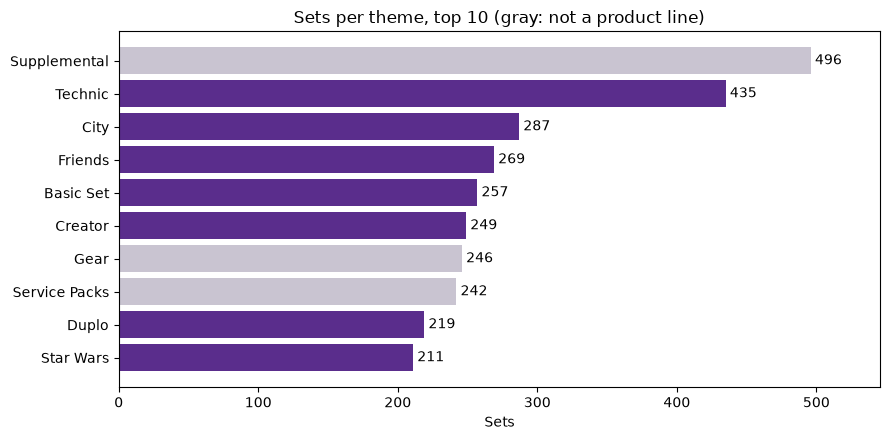

In [27]:
not_product_lines = ["Supplemental", "Gear", "Service Packs"]
theme_colors = np.where(top_themes["theme_name"].isin(not_product_lines), GRAY, PURPLE)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(top_themes["theme_name"], top_themes["number_of_sets"], color=theme_colors)
ax.bar_label(bars, padding=3)
ax.invert_yaxis()
ax.margins(x=0.1)
ax.set_title("Sets per theme, top 10 (gray: not a product line)")
ax.set_xlabel("Sets")
plt.tight_layout()
plt.show()

**Your turn 9: Theme detective.** Which theme does each of these sets belong to: "Taj Mahal", "Millennium Falcon - UCS" and "Death Star"? Use one query with `IN`. How many rows do you get, and why?

<details>
  <summary>Hint</summary>

Join `sets` and `themes` as above, and filter with `WHERE s.name IN ('Taj Mahal', 'Millennium Falcon - UCS', 'Death Star')`.

</details>

<details>
  <summary>Answer</summary>

```sql
SELECT s.name AS set_name,
       s.year,
       t.name AS theme_name
FROM sets AS s
JOIN themes AS t
  ON s.theme_id = t.id
WHERE s.name IN ('Taj Mahal', 'Millennium Falcon - UCS', 'Death Star')
```

4 rows, not 3: there are **two** sets called "Death Star" (2008 and 2016), in two different themes. The Taj Mahal is in Sculptures, and the 2007 Millennium Falcon is in "Star Wars Episode 4/5/6". A name is not a key: `set_num` is.

</details>

In [28]:
run("""
SELECT s.name AS set_name,
       s.year,
       t.name AS theme_name
FROM sets AS s
JOIN themes AS t
  ON s.theme_id = t.id
WHERE s.name IN ('Taj Mahal', 'Millennium Falcon - UCS', 'Death Star')
""")

,set_name,year,theme_name
0,Millennium Falcon - UCS,2007,Star Wars Episode 4/5/6
1,Death Star,2008,Star Wars Episode 4/5/6
2,Taj Mahal,2008,Sculptures
3,Death Star,2016,Star Wars


**My answer:** 4 rows, not 3. There are two sets called "Death Star" (2008 and 2016), in two different themes. A name is not a unique key: `set_num` is.

#### Insight:

<details>
  <summary>Reveal after you finish the Your turn questions above</summary>

- The theme with the most sets is "Supplemental" (496 sets): packs of extra bricks rather than models. Technic (435), City (287) and Friends (269) are the largest product lines.
- "Gear" and "Service Packs" are also near the top, although they are mostly accessories and replacement parts. A ranking is only as meaningful as the categories behind it.
- Themes are nested, and some names repeat under different parents ("Star Wars" appears several times). Grouping by `t.name` merges those rows, while grouping by `t.id` would keep them apart. Both are reasonable, as long as you know which one you chose.

</details>

### LEFT JOIN

A `LEFT JOIN` keeps **every row of the left table**, even when there is no match on the right. Where there is no match, the right side's columns are `NULL`. This makes it the tool for finding what is missing.

**Your turn 10: INNER or LEFT?** Count the themes that have **no sets** attached directly to them, using `themes AS t LEFT JOIN sets AS s` and `WHERE s.set_num IS NULL`. Then change `LEFT JOIN` to `JOIN` and run it again. Explain the new result.

<details>
  <summary>Hint</summary>

```
SELECT COUNT(*)
FROM themes AS t
LEFT JOIN sets AS s
  ON t.id = s.theme_id
WHERE ...
```

</details>

<details>
  <summary>Answer</summary>

```sql
SELECT COUNT(*) AS themes_without_sets
FROM themes AS t
LEFT JOIN sets AS s
  ON t.id = s.theme_id
WHERE s.set_num IS NULL
```

39 themes have no sets of their own (mostly parent themes that only hold sub-themes). With a plain `JOIN` the answer is **0**: an INNER JOIN throws away every theme without a match before `WHERE` even looks for them.

</details>

In [29]:
display(run("""
SELECT COUNT(*) AS themes_without_sets
FROM themes AS t
LEFT JOIN sets AS s
  ON t.id = s.theme_id
WHERE s.set_num IS NULL
"""))

run("""
SELECT COUNT(*) AS themes_without_sets
FROM themes AS t
JOIN sets AS s
  ON t.id = s.theme_id
WHERE s.set_num IS NULL
""")

,themes_without_sets
0,39


,themes_without_sets
0,0


**My answer:** 39 themes have no sets of their own, mostly parent themes that only hold sub-themes. With a plain `JOIN` the answer is 0, because an INNER JOIN drops every theme without a match before `WHERE` looks for them.

### Self joins and COALESCE

The `themes` table points to itself: `parent_id` holds the `id` of another theme. To show each theme next to its parent's **name**, we join `themes` to a second copy of itself, with two aliases, `child` and `parent`. We use a `LEFT JOIN` so that top level themes, which have no parent, are kept. `COALESCE(a, b)` returns `a`, or `b` when `a` is `NULL`, so missing parents get a readable label.

Interviewers love this pattern: the classic version is a table of employees in which each row points to the employee's manager.

In [30]:
run("""
SELECT child.id,
       child.name                         AS theme,
       COALESCE(parent.name, '(top level)') AS parent_theme
FROM themes AS child
LEFT JOIN themes AS parent
  ON child.parent_id = parent.id
WHERE child.id IN (1, 158, 171, 174, 494)
ORDER BY child.id
""")

,id,theme,parent_theme
0,1,Technic,(top level)
1,158,Star Wars,(top level)
2,171,Ultimate Collector Series,Star Wars
3,174,Star Wars Episode 4/5/6,Ultimate Collector Series
4,494,Friends,(top level)


### Watch the row count: joins can duplicate rows

`sets` has 11,673 rows, one per set. The `inventories` table lists the contents of each set, and a set can have more than one version of its contents. **Predict:** after joining the two tables, will there be more rows, fewer rows, or exactly 11,673?

In [31]:
run("""
SELECT (SELECT COUNT(*) FROM sets) AS rows_in_sets,
       (SELECT COUNT(*)
        FROM sets AS s
        JOIN inventories AS i
          ON s.set_num = i.set_num)  AS rows_after_join
""")

,rows_in_sets,rows_after_join
0,11673,11681


Which sets appear more than once? `GROUP BY` with `HAVING COUNT(*) > 1` is the standard way to find duplicates:

In [32]:
run("""
SELECT set_num,
       COUNT(*) AS inventory_versions
FROM inventories
GROUP BY set_num
HAVING COUNT(*) > 1
""")

,set_num,inventory_versions
0,11905-1,2
1,214.6-1,2
2,31015-1,2
3,421-2,5
4,6515-1,2
5,75053-1,2
6,8030-1,2
7,8880-1,2


8 sets have more than one inventory version (set `421-2` has five), so the join repeats them, while 3 sets with no inventory at all drop out. A sum over the joined table would count those 8 sets several times. **Always compare row counts before and after a join**, and in an interview, say out loud that you are checking for duplicates.

### Joining more than two tables

Joins can be chained: each extra `JOIN` follows one more arrow on the table map from Section 1.

### Data Story 4: The Colors of LEGO

Which colors does LEGO use most? The `inventory_parts` table records every part in every set, along with its `color_id` and how many pieces are included (`quantity`). Joining it to `colors` gives us readable color names. We leave out spare pieces (`is_spare = 't'`) so we only count parts that are used in the build.

**Predict:** which color do you think appears most often across all LEGO sets?

In [33]:
top_colors = run("""
SELECT c.name          AS color,
       c.rgb,
       SUM(ip.quantity) AS total_pieces
FROM inventory_parts AS ip
JOIN colors AS c
  ON ip.color_id = c.id
WHERE ip.is_spare = 'f'
GROUP BY c.name, c.rgb
ORDER BY total_pieces DESC
LIMIT 10
""")

top_colors

,color,rgb,total_pieces
0,Black,05131D,391036
1,White,FFFFFF,218948
2,Light Bluish Gray,A0A5A9,197316
3,Red,C91A09,168033
4,Dark Bluish Gray,6C6E68,146614
5,Yellow,F2CD37,118951
6,Blue,0055BF,116107
7,Light Gray,9BA19D,90729
8,Tan,E4CD9E,55640
9,Reddish Brown,582A12,46077


The `rgb` column stores each color as a hex code, so we can draw every bar in its real LEGO color.

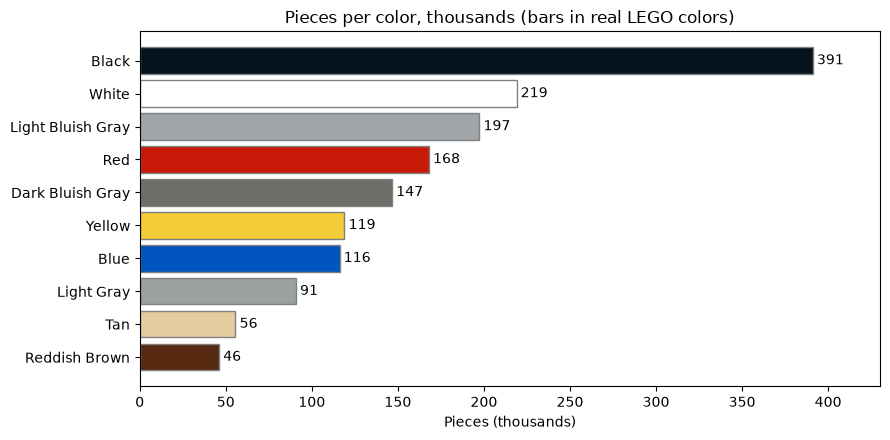

In [34]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(top_colors["color"], top_colors["total_pieces"] / 1000,
               color="#" + top_colors["rgb"], edgecolor="gray")
ax.bar_label(bars, fmt="{:.0f}", padding=3)
ax.invert_yaxis()
ax.margins(x=0.1)
ax.set_title("Pieces per color, thousands (bars in real LEGO colors)")
ax.set_xlabel("Pieces (thousands)")
plt.tight_layout()
plt.show()

Has the LEGO palette grown over time? To answer this we follow three arrows on the map: `inventory_parts` to `inventories` (to find the set), `inventories` to `sets` (to find the year), and `inventory_parts` to `colors`.

In [35]:
colors_per_decade = run("""
SELECT (s.year / 10) * 10           AS decade,
       COUNT(DISTINCT ip.color_id)  AS number_of_colors
FROM inventory_parts AS ip
JOIN inventories AS i
  ON ip.inventory_id = i.id
JOIN sets AS s
  ON i.set_num = s.set_num
GROUP BY decade
ORDER BY decade
""")

colors_per_decade

,decade,number_of_colors
0,1950,15
1,1960,15
2,1970,21
3,1980,27
4,1990,62
5,2000,117
6,2010,92


Notice how a question that sounds simple in English needed four tables. Being comfortable with joins is what makes SQL powerful.

#### Insight:

<details>
  <summary>Reveal after you finish the Your turn questions above</summary>

- Black is the most used color by far (391,036 pieces), followed by white, the two grays and the classic red, yellow and blue.
- The palette grew from 15 colors in the 1950s to 117 in the 2000s. The 2010s show fewer colors, partly because the data stops in 2017, and partly because LEGO deliberately reduced its number of colors in the mid-2000s to cut costs.
- Questions like these need several tables. JOINs are what let us follow a set to its parts, colors and years.

</details>

### Exercise 3 The biggest Technic sets

Join `sets` and `themes` to find the 10 sets with the most parts whose theme name is exactly `'Technic'`. Show the set name, year, number of parts and theme name.

<details>
  <summary>Hints</summary>

Start from the INNER JOIN example in this section, add `WHERE t.name = 'Technic'`, then `ORDER BY s.num_parts DESC LIMIT 10`.

</details>

In [36]:
run("""
SELECT s.name AS set_name,
       s.year,
       s.num_parts,
       t.name AS theme_name
FROM sets AS s
JOIN themes AS t
  ON s.theme_id = t.id
WHERE t.name = 'Technic'
ORDER BY s.num_parts DESC
LIMIT 10
""")

,set_name,year,num_parts,theme_name
0,Mercedes Benz Arocs 3245,2015,2792,Technic
1,Porsche 911 GT3 RS,2016,2704,Technic
2,Claas Xerion 5000 Trac VC,2016,1975,Technic
3,Technology Resource Set,1995,1730,Technic
4,"4 x 4 Crawler Exclusive Edition ""BOSS Crawler""...",2013,1583,Technic
5,Crawler Crane,2015,1399,Technic
6,Ocean Explorer,2017,1326,Technic
7,Logging Truck,2012,1311,Technic
8,Supercar,2011,1280,Technic
9,Service Truck,2013,1275,Technic


## 5. CTEs and Window Functions

### Common table expressions with WITH

A **common table expression** (CTE) gives a query result a temporary name at the top, with `WITH`, and then uses that name like a normal table. Long queries become small named steps that read top to bottom, like a Python script. We need CTEs for window functions below.

Here we first build a table of theme sizes, then keep themes with at least 20 sets and rank them by average size.

In [37]:
run("""
WITH theme_summary AS (
    SELECT t.name                     AS theme_name,
           COUNT(*)                   AS number_of_sets,
           ROUND(AVG(s.num_parts), 0) AS average_parts
    FROM sets AS s
    JOIN themes AS t
      ON s.theme_id = t.id
    GROUP BY t.name
)
SELECT *
FROM theme_summary
WHERE number_of_sets >= 20
ORDER BY average_parts DESC
LIMIT 10
""")

,theme_name,number_of_sets,average_parts
0,Sculptures,23,1717.0
1,Model,22,629.0
2,Star Wars Episode 4/5/6,148,593.0
3,Master Building Academy,21,539.0
4,Minecraft,27,509.0
5,Educational and Dacta,33,473.0
6,Ferrari,32,420.0
7,Universal Building Set,34,417.0
8,The LEGO Movie,29,392.0
9,Basic Set,257,391.0


### Window functions: calculations across rows

`GROUP BY` **collapses** many rows into one. A **window function** calculates across a group of rows but **keeps every row**, adding the answer as a new column. They are the most tested topic in data science SQL interviews.

```
FUNCTION() OVER (PARTITION BY column ORDER BY column)
```

- `OVER (...)` turns a function into a window function.
- `PARTITION BY` splits the rows into groups (like `GROUP BY`, but nothing collapses). Leave it out to use all rows.
- `ORDER BY` inside `OVER` sets the order used for ranking or for "previous row" and "running" calculations.

| Function | What it gives each row | Typical interview question |
|---|---|---|
| `ROW_NUMBER()` | 1, 2, 3, ... with no ties | top N per group |
| `RANK()` | ties share a rank, then a gap: 1, 2, 2, 4 | ranking with ties |
| `DENSE_RANK()` | ties share a rank, no gap: 1, 2, 2, 3 | the second-highest value |
| `LAG(column)` | the value from the previous row | change since last year |
| `SUM(column) OVER (ORDER BY ...)` | a running total | cumulative counts |
| `AVG(column) OVER (ORDER BY ... ROWS BETWEEN 2 PRECEDING AND CURRENT ROW)` | a moving average | smoothing a trend |

**Predict:** 1953 and 1959 both had exactly 4 sets. How will the three ranking functions treat that tie?

In [38]:
run("""
SELECT year,
       COUNT(*)                                AS number_of_sets,
       ROW_NUMBER() OVER (ORDER BY COUNT(*))   AS row_number,
       RANK()       OVER (ORDER BY COUNT(*))   AS rank,
       DENSE_RANK() OVER (ORDER BY COUNT(*))   AS dense_rank
FROM sets
GROUP BY year
ORDER BY number_of_sets
LIMIT 6
""")

,year,number_of_sets,row_number,rank,dense_rank
0,1960,3,1,1,1
1,1953,4,2,2,2
2,1959,4,3,2,2
3,1950,7,4,4,3
4,1965,10,5,5,4
5,1964,11,6,6,5


`ROW_NUMBER` breaks the tie arbitrarily (2 and 3), `RANK` gives both a 2 and skips 3, and `DENSE_RANK` gives both a 2 and continues with 3. Window functions run **after** `GROUP BY`, so they can rank the groups themselves (here, `COUNT(*)` per year).

### Top N per group

To keep the best row in each group, number the rows inside each group with `PARTITION BY`, then keep row 1. Window functions are calculated in the `SELECT` step, after `WHERE`, so we cannot filter on them in the same query: we calculate them in a CTE and filter in the main query. Below: the largest set of every decade.

In [39]:
run("""
WITH ranked AS (
    SELECT (year / 10) * 10 AS decade,
           name,
           year,
           num_parts,
           ROW_NUMBER() OVER (PARTITION BY (year / 10) * 10
                              ORDER BY num_parts DESC) AS position
    FROM sets
)
SELECT decade, name, year, num_parts
FROM ranked
WHERE position = 1
ORDER BY decade
""")

,decade,name,year,num_parts
0,1950,Gift Package,1957,244
1,1960,Town Plan - Continental European,1961,760
2,1970,U.S.S. Constellation,1978,973
3,1980,Teachers Resource Set,1985,1534
4,1990,Bonus Lego Basic Town,1996,2472
5,2000,Taj Mahal,2008,5922
6,2010,Window Exploration Bag,2010,5200


**Your turn 11: Top 3 per theme.** Find the **three largest sets** in each of the themes Technic, Friends and City. Show the theme, the set name, the year, the number of parts and the position (1, 2 or 3).

<details>
  <summary>Hint</summary>

Inside a CTE, join `sets` and `themes`, filter with `WHERE t.name IN ('Technic', 'Friends', 'City')`, and add `ROW_NUMBER() OVER (PARTITION BY t.name ORDER BY s.num_parts DESC) AS position`. In the main query keep `WHERE position <= 3`.

</details>

<details>
  <summary>Answer</summary>

```sql
WITH ranked AS (
    SELECT t.name AS theme,
           s.name AS set_name,
           s.year,
           s.num_parts,
           ROW_NUMBER() OVER (PARTITION BY t.name
                              ORDER BY s.num_parts DESC) AS position
    FROM sets AS s
    JOIN themes AS t
      ON s.theme_id = t.id
    WHERE t.name IN ('Technic', 'Friends', 'City')
)
SELECT *
FROM ranked
WHERE position <= 3
ORDER BY theme, position
```

City: Volcano Heavy-Lift Helicopter (1,273 parts), Volcano Exploration Base (823), Rocket Launch Center (498). Friends: Heartlake Grand Hotel (1,573), Heartlake Shopping Mall (1,165), Summer Riding Camp (1,158). Technic: Mercedes Benz Arocs 3245 (2,792), Porsche 911 GT3 RS (2,704), Claas Xerion 5000 Trac VC (1,975). "Top N per group" is one of the most common interview questions; this CTE plus `ROW_NUMBER` shape answers it every time.

</details>

In [40]:
run("""
WITH ranked AS (
    SELECT t.name AS theme,
           s.name AS set_name,
           s.year,
           s.num_parts,
           ROW_NUMBER() OVER (PARTITION BY t.name
                              ORDER BY s.num_parts DESC) AS position
    FROM sets AS s
    JOIN themes AS t
      ON s.theme_id = t.id
    WHERE t.name IN ('Technic', 'Friends', 'City')
)
SELECT *
FROM ranked
WHERE position <= 3
ORDER BY theme, position
""")

,theme,set_name,year,num_parts,position
0,City,Volcano Heavy-Lift Helicopter,2016,1273,1
1,City,Volcano Exploration Base,2016,823,2
2,City,Rocket Launch Center,2011,498,3
3,Friends,Heartlake Grand Hotel,2015,1573,1
4,Friends,Heartlake Shopping Mall,2014,1165,2
5,Friends,Summer Riding Camp,2012,1158,3
6,Technic,Mercedes Benz Arocs 3245,2015,2792,1
7,Technic,Porsche 911 GT3 RS,2016,2704,2
8,Technic,Claas Xerion 5000 Trac VC,2016,1975,3


### Comparing rows: LAG, running totals and moving averages

`LAG(column)` looks one row back. Subtracting it from the current value gives the change since the previous year. `SUM(...) OVER (ORDER BY year)` adds up everything so far, and `AVG(...) OVER (... ROWS BETWEEN 2 PRECEDING AND CURRENT ROW)` averages each year with the two before it.

The first CTE counts the sets per year; the second adds the window columns. We filter to 2010 and later only at the end, so that 2010 can still look back at 2009.

In [41]:
run("""
WITH yearly AS (
    SELECT year,
           COUNT(*) AS number_of_sets
    FROM sets
    GROUP BY year
),
with_windows AS (
    SELECT year,
           number_of_sets,
           LAG(number_of_sets) OVER (ORDER BY year)  AS previous_year,
           SUM(number_of_sets) OVER (ORDER BY year)  AS running_total,
           ROUND(AVG(number_of_sets) OVER (ORDER BY year
                 ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 1) AS three_year_average
    FROM yearly
)
SELECT year,
       number_of_sets,
       previous_year,
       number_of_sets - previous_year                                 AS change,
       ROUND(100.0 * (number_of_sets - previous_year) / previous_year, 1) AS percent_change,
       running_total,
       three_year_average
FROM with_windows
WHERE year >= 2010
""")

,year,number_of_sets,previous_year,change,percent_change,running_total,three_year_average
0,2010,444,402,42,10.4,7692,398.3
1,2011,503,444,59,13.3,8195,449.7
2,2012,615,503,112,22.3,8810,520.7
3,2013,593,615,-22,-3.6,9403,570.3
4,2014,713,593,120,20.2,10116,640.3
5,2015,665,713,-48,-6.7,10781,657.0
6,2016,596,665,-69,-10.4,11377,658.0
7,2017,296,596,-300,-50.3,11673,519.0


By the end of 2017 LEGO had released 11,673 sets in total. The 2017 row shows a drop of 300 sets (minus 50%): the incomplete year again. The three-year average smooths out the jumps.

**Your turn 12: The biggest jump.** Using `LAG`, find the year with the **biggest increase** in sets compared with the year before. Then sort the other way to find the biggest decrease. Which row appears first when you sort by `change` from smallest to largest, and why?

<details>
  <summary>Hint</summary>

Reuse the `yearly` CTE from above. Add `number_of_sets - LAG(number_of_sets) OVER (ORDER BY year) AS change` in a second step, then `ORDER BY change DESC LIMIT 3`.

</details>

<details>
  <summary>Answer</summary>

```sql
WITH yearly AS (
    SELECT year,
           COUNT(*) AS number_of_sets
    FROM sets
    GROUP BY year
),
changes AS (
    SELECT year,
           number_of_sets,
           number_of_sets - LAG(number_of_sets) OVER (ORDER BY year) AS change
    FROM yearly
)
SELECT *
FROM changes
ORDER BY change DESC
LIMIT 3
```

The biggest jump is 1998 (+133, from 192 to 325 sets), then 2014 (+120) and 2012 (+112). Sorted the other way, **1950 comes first**: it has no previous year, so `LAG` gives `NULL`, and SQLite puts `NULL` first in an ascending sort. After it come 2017 (-300, the incomplete year) and 1988 (-141). Add `WHERE change IS NOT NULL` to remove the empty row.

</details>

In [42]:
display(run("""
WITH yearly AS (
    SELECT year,
           COUNT(*) AS number_of_sets
    FROM sets
    GROUP BY year
),
changes AS (
    SELECT year,
           number_of_sets,
           number_of_sets - LAG(number_of_sets) OVER (ORDER BY year) AS change
    FROM yearly
)
SELECT *
FROM changes
ORDER BY change DESC
LIMIT 3
"""))

run("""
WITH yearly AS (
    SELECT year,
           COUNT(*) AS number_of_sets
    FROM sets
    GROUP BY year
),
changes AS (
    SELECT year,
           number_of_sets,
           number_of_sets - LAG(number_of_sets) OVER (ORDER BY year) AS change
    FROM yearly
)
SELECT *
FROM changes
ORDER BY change ASC
LIMIT 3
""")

,year,number_of_sets,change
0,1998,325,133
1,2014,713,120
2,2012,615,112


,year,number_of_sets,change
0,1950,7,NaN
1,2017,296,-300.0
2,1988,68,-141.0


**My answer:** The biggest jump is 1998 (+133 sets, from 192 to 325), then 2014 (+120) and 2012 (+112). Sorted from smallest to largest, **1950** comes first. It has no previous year, so `LAG` returns `NULL`, and SQLite sorts `NULL` first in an ascending sort. Add `WHERE change IS NOT NULL` to remove that row.

### Exercise 4 Window functions

1. For the theme `'Star Wars'`, show each year, the number of sets released that year, and the **running total** of Star Wars sets so far.
2. For each theme with at least 100 sets, show its number of sets and its **share of all sets** in the database, as a percentage. Sort from the largest share.

<details>
  <summary>Hints</summary>

1. Count Star Wars sets per year in a CTE, then add `SUM(number_of_sets) OVER (ORDER BY year)`.
2. `SUM(COUNT(*)) OVER ()` is the total of all the groups. Divide by it with `100.0 *`, and use `HAVING COUNT(*) >= 100`. Think about whether the share should be out of all sets or only the themes you kept.

</details>

In [43]:
display(run("""
WITH star_wars_per_year AS (
    SELECT s.year,
           COUNT(*) AS number_of_sets
    FROM sets AS s
    JOIN themes AS t
      ON s.theme_id = t.id
    WHERE t.name = 'Star Wars'
    GROUP BY s.year
)
SELECT year,
       number_of_sets,
       SUM(number_of_sets) OVER (ORDER BY year) AS running_total
FROM star_wars_per_year
ORDER BY year
"""))

run("""
SELECT t.name AS theme_name,
       COUNT(*) AS number_of_sets,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM sets), 2) AS share_of_all_sets_percent
FROM sets AS s
JOIN themes AS t
  ON s.theme_id = t.id
GROUP BY t.name
HAVING COUNT(*) >= 100
ORDER BY share_of_all_sets_percent DESC
""")

,year,number_of_sets,running_total
0,1999,1,1
1,2000,4,5
2,2001,3,8
3,2002,7,15
4,2003,1,16
5,2009,1,17
6,2010,1,18
7,2011,28,46
8,2012,35,81
9,2013,31,112


,theme_name,number_of_sets,share_of_all_sets_percent
0,Supplemental,496,4.25
1,Technic,435,3.73
2,City,287,2.46
3,Friends,269,2.30
4,Basic Set,257,2.20
5,Creator,249,2.13
6,Gear,246,2.11
7,Service Packs,242,2.07
8,Duplo,219,1.88
9,Star Wars,211,1.81


**My answer:** The share should be out of all 11,673 sets in the database, not only the themes that are kept. That is why the query uses a subquery for the total. `SUM(COUNT(*)) OVER ()` would add up only the themes left after `HAVING`, so it would be the wrong denominator.

## 6. Putting It Together

### Building a complex query, one line at a time

A long query is just short steps stacked in the right order. Use the six questions from the slides: what is one row of the answer, which tables, which rows, which groups, which groups to keep, which columns and order. **Never write a long query in one go**: run it after every step and check the result.

Question: **which themes got the most sets from 2010 on?** One row of the answer is one theme. The comments show the step that wrote each line.

In [44]:
run("""
SELECT t.name   AS theme_name,              -- step 6: the columns we want
       COUNT(*) AS number_of_sets
FROM sets AS s                              -- step 2: the tables
JOIN themes AS t
  ON s.theme_id = t.id
WHERE s.year >= 2010                        -- step 3: the rows
GROUP BY t.name                             -- step 4: one group per theme
ORDER BY number_of_sets DESC                -- step 6: order and size
LIMIT 5
""")

,theme_name,number_of_sets
0,Friends,269
1,Gear,211
2,Star Wars,194
3,Ninjago,191
4,Duplo,169


Friends leads the 2010s, and Star Wars appears now that we look at recent years only. Try deleting the last lines one at a time and rerun: you will see the query grow from 4,425 rows to 204 groups to 5 answers.

### The order SQL runs in

We **write** `SELECT` first, but the database **runs** the clauses in this order (see the slide): `FROM` and `JOIN`, `WHERE`, `GROUP BY`, `HAVING`, `SELECT` (where window functions are calculated), `ORDER BY`, `LIMIT`. So `WHERE` cannot use `COUNT(*)`, because the groups do not exist yet, and it cannot use a window function either, which is why we used CTEs in Section 5.

**Common mistakes**

- Double quotes for text. Use single quotes: `'Technic'`.
- `= NULL` instead of `IS NULL`.
- Selecting a column that is neither grouped nor aggregated.
- A `JOIN` without `ON`, which matches every row with every other row.
- An aggregate condition in `WHERE` instead of `HAVING`.

**Predict:** the query in the next cell tries to keep only the years with more than 500 sets. Will it work? If not, which mistake from the list above does it make?

In [45]:
try:
    display(run("""
    SELECT year,
           COUNT(*) AS number_of_sets
    FROM sets
    WHERE COUNT(*) > 500
    GROUP BY year
    """))
except Exception as error:
    print("Error:", error)

Error: Execution failed on sql '
    SELECT year,
           COUNT(*) AS number_of_sets
    FROM sets
    WHERE COUNT(*) > 500
    GROUP BY year
    ': misuse of aggregate: COUNT()


**The fix.** `WHERE` runs before `GROUP BY`, so the counts do not exist yet when `WHERE` runs. SQLite says "misuse of aggregate". Moving the condition to `HAVING`, which runs after the groups are made, fixes it and returns the six years from 2011 to 2016.

In [46]:
run("""
SELECT year,
       COUNT(*) AS number_of_sets
FROM sets
GROUP BY year
HAVING COUNT(*) > 500
ORDER BY year
""")

,year,number_of_sets
0,2011,503
1,2012,615
2,2013,593
3,2014,713
4,2015,665
5,2016,596


**Your turn 13: The top theme of every decade.** Which theme released the most sets in each decade? Build it in two steps with `WITH`:

1. Count the sets per decade and theme.
2. Rank the themes inside each decade with a window function, and keep the top one.

Use `RANK()` rather than `ROW_NUMBER()`. Look at the 1970s: why does it matter?

<details>
  <summary>Hint</summary>

Step 1 is a `GROUP BY (s.year / 10) * 10, t.name` with `COUNT(*)`. Step 2: `RANK() OVER (PARTITION BY decade ORDER BY number_of_sets DESC) AS position`. The main query keeps `WHERE position = 1`.

</details>

<details>
  <summary>Answer</summary>

```sql
WITH counts AS (
    SELECT (s.year / 10) * 10 AS decade,
           t.name             AS theme,
           COUNT(*)           AS number_of_sets
    FROM sets AS s
    JOIN themes AS t
      ON s.theme_id = t.id
    GROUP BY decade, t.name
),
ranked AS (
    SELECT decade,
           theme,
           number_of_sets,
           RANK() OVER (PARTITION BY decade
                        ORDER BY number_of_sets DESC) AS position
    FROM counts
)
SELECT decade, theme, number_of_sets
FROM ranked
WHERE position = 1
ORDER BY decade
```

Supplemental leads the 1950s and 1960s, Technic the 1980s and 1990s, City the 2000s and Friends the 2010s. The 1970s is a **tie**: Construction and Supplemental both have 50 sets. `RANK` keeps both rows; `ROW_NUMBER` would silently drop one of them. This query uses `JOIN`, `GROUP BY`, a CTE and a window function together: it is a realistic interview question.

</details>

In [47]:
run("""
WITH counts AS (
    SELECT (s.year / 10) * 10 AS decade,
           t.name             AS theme,
           COUNT(*)           AS number_of_sets
    FROM sets AS s
    JOIN themes AS t
      ON s.theme_id = t.id
    GROUP BY decade, t.name
),
ranked AS (
    SELECT decade,
           theme,
           number_of_sets,
           RANK() OVER (PARTITION BY decade
                        ORDER BY number_of_sets DESC) AS position
    FROM counts
)
SELECT decade, theme, number_of_sets
FROM ranked
WHERE position = 1
ORDER BY decade
""")

,decade,theme,number_of_sets
0,1950,Supplemental,88
1,1960,Supplemental,151
2,1970,Construction,50
3,1970,Supplemental,50
4,1980,Technic,124
5,1990,Technic,154
6,2000,City,142
7,2010,Friends,269


**My answer:** The 1970s is a tie: Construction and Supplemental both have 50 sets. `RANK` keeps both rows, while `ROW_NUMBER` would silently drop one of them.

### Summary

| Task | SQL |
|---|---|
| Choose columns | `SELECT col1, col2` |
| Choose the table | `FROM table` |
| Rename a column | `AS new_name` |
| Remove duplicates | `DISTINCT` |
| Filter rows | `WHERE condition` |
| Sort | `ORDER BY col DESC` |
| Keep the first rows | `LIMIT n` |
| Summarize | `COUNT`, `SUM`, `AVG`, `MIN`, `MAX` |
| Summarize per group | `GROUP BY col` |
| Filter groups | `HAVING condition` |
| Create categories | `CASE WHEN ... THEN ... ELSE ... END` |
| Combine tables | `JOIN ... ON ...`, `LEFT JOIN ... ON ...` |
| Name a step | `WITH name AS (...)` |
| Replace a missing value | `COALESCE(column, 'label')` |
| Count only some rows | `SUM(CASE WHEN ... THEN 1 ELSE 0 END)` |
| Number or rank rows | `ROW_NUMBER()`, `RANK()`, `DENSE_RANK()` `OVER (...)` |
| Look at the previous row | `LAG(column) OVER (ORDER BY ...)` |
| Running total | `SUM(column) OVER (ORDER BY ...)` |

### Exercise 5 Interview practice

Classic data science interview questions, all on the LEGO data. Write each in its own cell.

1. **Second largest.** Find the set with the second-highest number of parts. Write it once with `ORDER BY` and `LIMIT ... OFFSET`, and once with `DENSE_RANK()`. When would the two answers differ?
2. **Duplicates.** Find every pair of `name` and `year` that appears more than once in `sets`. How many such pairs are there?
3. **Combine results.** Use `UNION ALL` to list, in one result, the names of all sets containing "Hogwarts" and the names of all themes containing "Harry". Add a column that says whether each row is a set or a theme.
4. **Top 3 per group on a summary.** For each decade, find the 3 colors with the most pieces (leave out spare pieces).
5. **Explain it.** In two sentences, explain to an interviewer the difference between `WHERE` and `HAVING`, and between `RANK()` and `DENSE_RANK()`.

<details>
  <summary>Hints</summary>

1. `LIMIT 1 OFFSET 1` skips the first row. With `DENSE_RANK() OVER (ORDER BY num_parts DESC)` inside a CTE, keep rank 2. They differ when two sets tie for first place.
2. `GROUP BY name, year` with `HAVING COUNT(*) > 1`. Wrap it in `SELECT COUNT(*) FROM (...)` to count the pairs.
3. Both `SELECT`s need the same number of columns: `SELECT 'set' AS kind, name FROM sets WHERE ... UNION ALL SELECT 'theme', name FROM themes WHERE ...`.
4. Join `inventory_parts`, `inventories`, `sets` and `colors`, `GROUP BY decade, color` in a CTE, then `ROW_NUMBER() OVER (PARTITION BY decade ORDER BY pieces DESC)`.

</details>

In [48]:
display(run("""
SELECT name, num_parts
FROM sets
ORDER BY num_parts DESC
LIMIT 1 OFFSET 1
"""))

run("""
WITH ranked AS (
    SELECT name,
           num_parts,
           DENSE_RANK() OVER (ORDER BY num_parts DESC) AS position
    FROM sets
)
SELECT name, num_parts
FROM ranked
WHERE position = 2
""")

,name,num_parts
0,Star Wars / M&M Mosaic - Promo Set,5461


,name,num_parts
0,Star Wars / M&M Mosaic - Promo Set,5461


**My answer:** Here both queries return the same set, "Star Wars / M&M Mosaic - Promo Set" (5,461 parts), because the largest set, the Taj Mahal, is not tied with anything. The two answers differ when two sets tie for first place. `LIMIT 1 OFFSET 1` then returns the second row, which is the tied top set, while `DENSE_RANK() = 2` skips the tie and returns the next lower value.

In [49]:
display(run("""
SELECT name, year, COUNT(*) AS times_in_database
FROM sets
GROUP BY name, year
HAVING COUNT(*) > 1
ORDER BY times_in_database DESC, name
"""))

run("""
SELECT COUNT(*) AS duplicate_pairs
FROM (
    SELECT name, year
    FROM sets
    GROUP BY name, year
    HAVING COUNT(*) > 1
)
""")

,name,year,times_in_database
0,Basic Building Set,1985,22
1,Basic Building Set,1987,12
2,Basic Building Set,1990,11
3,Basic Set,1973,8
4,Basic Set,1981,8
...,...,...,...
201,XL Bucket,1992,2
202,Z-95 Headhunter,2013,2
203,Zane foil pack,2015,2
204,Zo Weevil,1999,2


,duplicate_pairs
0,206


**My answer:** 206 pairs of `name` and `year` appear more than once. The most repeated pair is "Basic Building Set" in 1985, with 22 sets.

In [50]:
run("""
SELECT 'set' AS kind, name
FROM sets
WHERE name LIKE '%Hogwarts%'
UNION ALL
SELECT 'theme' AS kind, name
FROM themes
WHERE name LIKE '%Harry%'
""")

,kind,name
0,set,Motorized Hogwarts Express
1,set,Hogwarts
2,set,Mini Hogwarts Express
3,set,Hogwarts Express
4,set,Hogwarts Castle
5,set,Hogwarts Classroom
6,set,Hogwarts Castle (2nd edition)
7,set,Hogwarts Express (2nd edition)
8,set,Hogwarts Express (3rd edition)
9,set,Hogwarts Castle [Fourth Edition]


In [51]:
run("""
WITH color_pieces AS (
    SELECT (s.year / 10) * 10 AS decade,
           c.name             AS color,
           SUM(ip.quantity)   AS pieces
    FROM inventory_parts AS ip
    JOIN colors AS c
      ON ip.color_id = c.id
    JOIN inventories AS i
      ON ip.inventory_id = i.id
    JOIN sets AS s
      ON i.set_num = s.set_num
    WHERE ip.is_spare = 'f'
    GROUP BY decade, c.name
),
ranked AS (
    SELECT decade,
           color,
           pieces,
           ROW_NUMBER() OVER (PARTITION BY decade
                              ORDER BY pieces DESC) AS position
    FROM color_pieces
)
SELECT decade, position, color, pieces
FROM ranked
WHERE position <= 3
ORDER BY decade, position
""")

,decade,position,color,pieces
0,1950,1,White,1804
1,1950,2,Red,979
2,1950,3,Blue,542
3,1960,1,Red,5396
4,1960,2,White,4946
5,1960,3,Blue,3187
6,1970,1,Red,14890
7,1970,2,Black,12296
8,1970,3,Yellow,10150
9,1980,1,Black,25909


**Explain it (interview answer):** `WHERE` filters rows before they are grouped, while `HAVING` filters groups after they are made, so conditions on `COUNT(*)` or `AVG(...)` belong in `HAVING`. `RANK()` leaves a gap after a tie (1, 2, 2, 4), while `DENSE_RANK()` does not (1, 2, 2, 3).